# Daily Crude Oil Data Exploration

This notebook explores the validated daily WTI crude oil (CL) data produced by `src/prepare_daily_data.py`. It reads only files in `data/processed/`; run the preparation script first:

```bash
python src/prepare_daily_data.py --config config/prepare_daily.yaml
```

Sections: data quality, price history, returns distribution, liquidity (volume by weekday and by days to expiry), gaps, and roll effects. The daily file contains no intraday timestamps, so volume by time of day needs the 1-minute data planned for the intraday horizon.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(path for path in (Path("."), Path("..")) if (path / "data/processed").exists())
processed = root / "data/processed"
figures = root / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)

continuous = pd.read_parquet(processed / "cl_daily_continuous.parquet")
contracts = pd.read_parquet(processed / "cl_daily_contracts.parquet")
rolls = pd.read_csv(processed / "cl_daily_roll_calendar.csv", parse_dates=["roll_date", "gap_date", "from_last_trade_date"])
summary = pd.read_csv(processed / "cl_daily_quality_summary.csv")
crosscheck = pd.read_csv(processed / "cl_daily_roll_crosscheck.csv", parse_dates=["roll_date"])

# Chart style: one axis per chart, thin lines, recessive grid, text in neutral ink.
RAW, ADJUSTED, THIRD = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 1.2, "legend.frameon": False, "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

print(f"Continuous sessions: {len(continuous):,} ({continuous['trade_date'].min().date()} to {continuous['trade_date'].max().date()})")
print(f"Contract sessions:   {len(contracts):,} across {contracts['contract_id'].nunique()} contracts")
print(f"Rolls:               {len(rolls)}")

Continuous sessions: 4,110 (2010-06-07 to 2026-10-07)
Contract sessions:   98,818 across 248 contracts
Rolls:               196


## 1. Data-quality summary

Produced by the preparation script. Flags are reported, never silently removed.

In [2]:
with pd.option_context("display.max_colwidth", 140):
    display(summary)

,check,value,note
0,raw_rows,777383,NaN
1,raw_ts_monotonic_in_file,True,NaN
2,raw_missing_values,0,NaN
3,non_outright_rows_excluded,667421,calendar spreads and other strategies
4,outright_rows,109962,NaN
5,duplicate_instrument_timestamp_rows_removed,0,NaN
6,ts_monotonic_within_each_instrument,True,NaN
7,sunday_bars_folded,9267,"Sunday-evening open, part of Monday's session"
8,holiday_bars_folded,1963,early-halt holiday sessions settle on the next trade date
9,session_rows,98818,NaN


## 2. Price history

`close` is the raw price of the contract held on each date, used for P&L. `signal_close` is the additively back-adjusted series, used for moving-average signals. Back-adjustment shifts history by the sum of later roll gaps, so its level is not a historical price, and it can be negative: use it only for price differences such as moving-average crossovers, not for percentage returns.

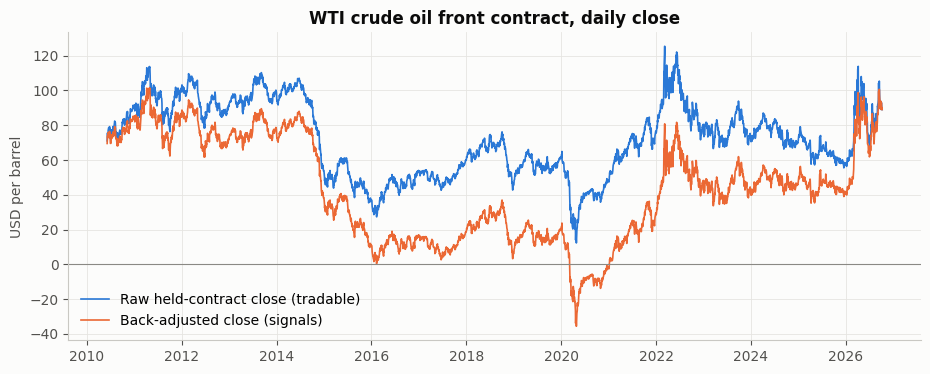

Back-adjustment ranges from -50.13 to 0.00 USD/bbl
Minimum raw close in the held series: 12.26 on 2020-04-27


In [3]:
fig, ax = plt.subplots()
ax.plot(continuous["trade_date"], continuous["close"], color=RAW, label="Raw held-contract close (tradable)")
ax.plot(continuous["trade_date"], continuous["signal_close"], color=ADJUSTED, label="Back-adjusted close (signals)")
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_title("WTI crude oil front contract, daily close")
ax.set_ylabel("USD per barrel")
ax.legend(loc="lower left")
fig.savefig(figures / "daily_price_history.png")
plt.show()

adjustment_range = continuous["back_adjustment"].agg(["min", "max"])
print(f"Back-adjustment ranges from {adjustment_range['min']:.2f} to {adjustment_range['max']:.2f} USD/bbl")
print(f"Minimum raw close in the held series: {continuous['close'].min():.2f} on {continuous.loc[continuous['close'].idxmin(), 'trade_date'].date()}")

## 3. Returns distribution

Daily returns are measured within one contract: on a roll date the return is the new contract's close over its own previous close, so roll gaps never enter the returns. These are the returns a one-contract position actually earns.

,value
observations,4109.000000
mean daily return,0.000258
daily std,0.025305
annualized volatility (252),0.401709
skewness,-0.611108
excess kurtosis,20.660276
1% quantile,-0.066962
99% quantile,0.061106
days with |return| > 10%,26.000000


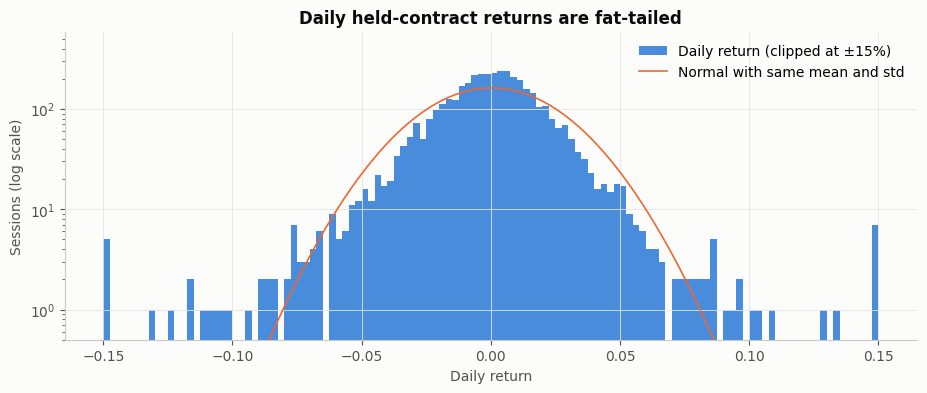

In [4]:
previous_close = contracts.sort_values("trade_date").groupby("instrument_id")["close"].shift()
contracts["prev_close"] = previous_close
returns = continuous.merge(contracts[["trade_date", "instrument_id", "prev_close"]], on=["trade_date", "instrument_id"], how="left")
returns["ret"] = returns["close"] / returns["prev_close"] - 1
returns["pnl_per_bbl"] = returns["close"] - returns["prev_close"]
r = returns["ret"].dropna()

stats = pd.Series({
    "observations": len(r),
    "mean daily return": r.mean(),
    "daily std": r.std(),
    "annualized volatility (252)": r.std() * np.sqrt(252),
    "skewness": r.skew(),
    "excess kurtosis": r.kurt(),
    "1% quantile": r.quantile(0.01),
    "99% quantile": r.quantile(0.99),
    "days with |return| > 10%": int((r.abs() > 0.10).sum()),
})
display(stats.to_frame("value"))

fig, ax = plt.subplots()
clipped = r.clip(-0.15, 0.15)
ax.hist(clipped, bins=120, color=RAW, alpha=0.85, label="Daily return (clipped at ±15%)")
grid = np.linspace(-0.15, 0.15, 400)
density = np.exp(-0.5 * ((grid - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi))
ax.plot(grid, density * len(r) * (0.30 / 120), color=ADJUSTED, label="Normal with same mean and std")
ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_title("Daily held-contract returns are fat-tailed")
ax.set_xlabel("Daily return")
ax.set_ylabel("Sessions (log scale)")
ax.legend()
fig.savefig(figures / "daily_returns_distribution.png")
plt.show()

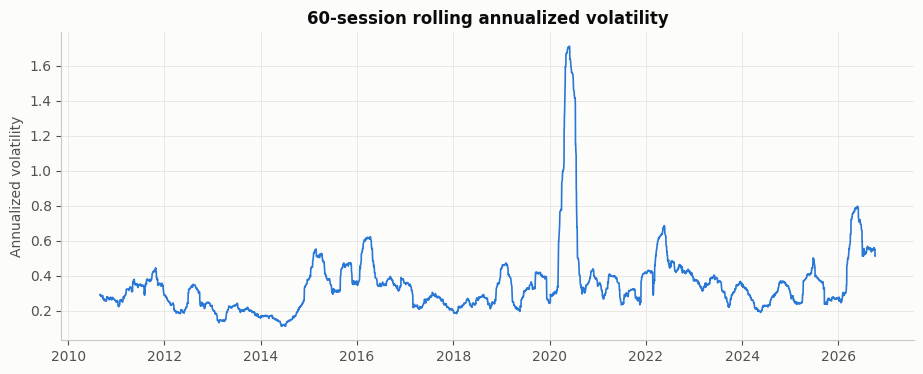

,sessions,annualized_vol,total_return
year,,,
2010,145,0.265,0.212
2011,252,0.344,-0.008
2012,252,0.248,-0.119
2013,252,0.189,0.049
2014,248,0.239,-0.423
2015,252,0.420,-0.448
2016,252,0.434,0.100
2017,251,0.243,0.028
2018,252,0.310,-0.218


In [5]:
rolling_vol = returns.set_index("trade_date")["ret"].rolling(60).std() * np.sqrt(252)
fig, ax = plt.subplots()
ax.plot(rolling_vol.index, rolling_vol, color=RAW)
ax.set_title("60-session rolling annualized volatility")
ax.set_ylabel("Annualized volatility")
fig.savefig(figures / "daily_rolling_volatility.png")
plt.show()

yearly = returns.assign(year=returns["trade_date"].dt.year).groupby("year")["ret"].agg(
    sessions="count", annualized_vol=lambda x: x.std() * np.sqrt(252), total_return=lambda x: (1 + x).prod() - 1
)
display(yearly.round(3))

## 4. Liquidity

Daily bars cannot show volume by time of day. Instead, the charts below show how volume moves from the expiring contract to the next one, which determines when to roll, and how held-contract volume varies by weekday and over time.

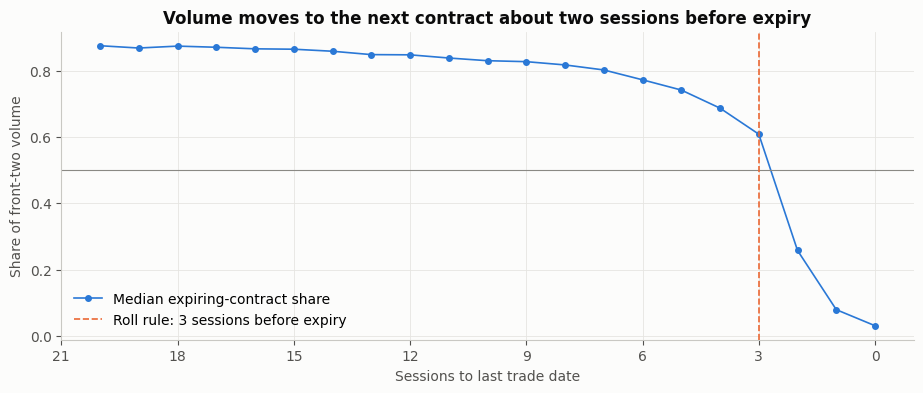

,median expiring share
sessions_to_expiry,
0,0.031
1,0.079
2,0.258
3,0.608
4,0.687
5,0.741
6,0.772
7,0.802
8,0.817


In [6]:
next_listed = (
    contracts[["instrument_id", "contract_month"]].drop_duplicates().sort_values("contract_month")
    .assign(next_id=lambda d: d["instrument_id"].shift(-1)).set_index("instrument_id")["next_id"]
)
volume = contracts.set_index(["trade_date", "instrument_id"])["volume"]
front = contracts[contracts["sessions_to_expiry"].between(0, 20)].copy()
front["next_id"] = front["instrument_id"].map(next_listed)
front["next_volume"] = [volume.get((d, n), np.nan) for d, n in zip(front["trade_date"], front["next_id"])]
front["front_share"] = front["volume"] / (front["volume"] + front["next_volume"])
share = front.groupby("sessions_to_expiry")["front_share"].median()

fig, ax = plt.subplots()
ax.plot(share.index, share.values, color=RAW, marker="o", markersize=4, label="Median expiring-contract share")
ax.axhline(0.5, color="#8a8984", linewidth=0.8)
ax.axvline(3, color=ADJUSTED, linewidth=1.2, linestyle="--", label="Roll rule: 3 sessions before expiry")
ax.invert_xaxis()
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("Volume moves to the next contract about two sessions before expiry")
ax.set_xlabel("Sessions to last trade date")
ax.set_ylabel("Share of front-two volume")
ax.legend(loc="lower left")
fig.savefig(figures / "daily_volume_migration.png")
plt.show()
display(share.loc[:8].round(3).to_frame("median expiring share"))

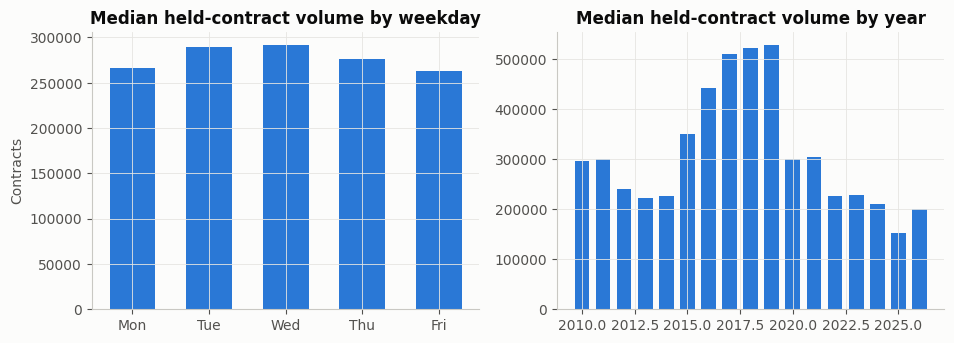

In [7]:
held = continuous.assign(weekday=continuous["trade_date"].dt.day_name(), year=continuous["trade_date"].dt.year)
by_weekday = held.groupby("weekday")["volume"].median().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
by_year = held.groupby("year")["volume"].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(by_weekday.index.str[:3], by_weekday.values, color=RAW, width=0.6)
axes[0].set_title("Median held-contract volume by weekday")
axes[0].set_ylabel("Contracts")
axes[1].bar(by_year.index, by_year.values, color=RAW, width=0.7)
axes[1].set_title("Median held-contract volume by year")
fig.savefig(figures / "daily_volume_weekday_year.png")
plt.show()

## 5. Gaps

Two kinds of gaps matter. **Data gaps** are trade dates with no data. **Price gaps** are moves between the previous close and the next open. They matter because the strategy executes at the next session's open.

In [8]:
calendar_gaps = summary.set_index("check").loc[
    ["trade_dates_without_any_outright", "sunday_bars_folded", "holiday_bars_folded", "continuous_missing_trade_dates", "continuous_degraded_sessions"],
    ["value", "note"],
]
display(calendar_gaps)

degraded_held = continuous.loc[continuous["degraded_date"], ["trade_date", "contract_id", "close", "volume"]]
print(f"Held-contract sessions on Databento degraded dates: {len(degraded_held)}")
display(degraded_held.head(10))

,value,note
check,,
trade_dates_without_any_outright,4,"2014-06-13, 2014-09-23, 2014-09-24, 2014-09-25..."
sunday_bars_folded,9267,"Sunday-evening open, part of Monday's session"
holiday_bars_folded,1963,early-halt holiday sessions settle on the next...
continuous_missing_trade_dates,4,NaN
continuous_degraded_sessions,27,"flagged, not removed"


Held-contract sessions on Databento degraded dates: 27


,trade_date,contract_id,close,volume
1012,2014-06-11,CLN2014,104.44,167229
1013,2014-06-12,CLN2014,106.82,301465
1014,2014-06-16,CLN2014,106.72,187615
1082,2014-09-22,CLX2014,90.65,220996
1872,2017-11-13,CLZ2017,56.73,429733
2108,2018-10-22,CLZ2018,69.59,426810
2166,2019-01-15,CLG2019,51.89,560890
2192,2019-02-22,CLJ2019,57.07,410158
2205,2019-03-13,CLJ2019,58.33,487845
2214,2019-03-26,CLK2019,59.86,560378


Close-to-open gap: median |gap| 0.0132%, 99th percentile |gap| 1.72%
Monday opens (after the weekend): median |gap| 0.1375%


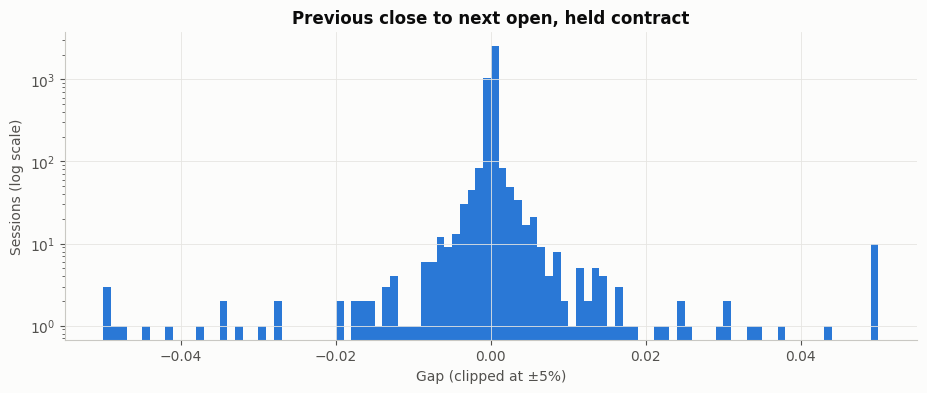

In [9]:
returns["open_gap"] = returns["open"] / returns["prev_close"] - 1
gap = returns["open_gap"].dropna()
monday = returns.loc[returns["trade_date"].dt.dayofweek.eq(0), "open_gap"].dropna()
print(f"Close-to-open gap: median |gap| {gap.abs().median():.4%}, 99th percentile |gap| {gap.abs().quantile(0.99):.2%}")
print(f"Monday opens (after the weekend): median |gap| {monday.abs().median():.4%}")

fig, ax = plt.subplots()
ax.hist(gap.clip(-0.05, 0.05), bins=100, color=RAW)
ax.set_yscale("log")
ax.set_title("Previous close to next open, held contract")
ax.set_xlabel("Gap (clipped at ±5%)")
ax.set_ylabel("Sessions (log scale)")
fig.savefig(figures / "daily_open_gaps.png")
plt.show()

The opening gap is small because the UTC daily bar opens at 00:00 UTC, about two hours into CME's evening session, and the previous UTC bar already includes those first hours. So the `open` of a daily bar is not the CME session open. The README section on limitations discusses this.

## 6. Roll effects

The roll gap is the next contract's close minus the expiring contract's close on the last session before the roll. A positive gap means contango (the next month is more expensive); a negative gap means backwardation. An unadjusted series would show these gaps as fake price moves.

,"roll gap, USD/bbl"
count,196.000
mean,-0.008
std,1.006
min,-4.710
25%,-0.385
50%,0.145
75%,0.412
max,6.150


Contango rolls: 58%; mean |gap| 0.62 USD/bbl = 620 USD per contract


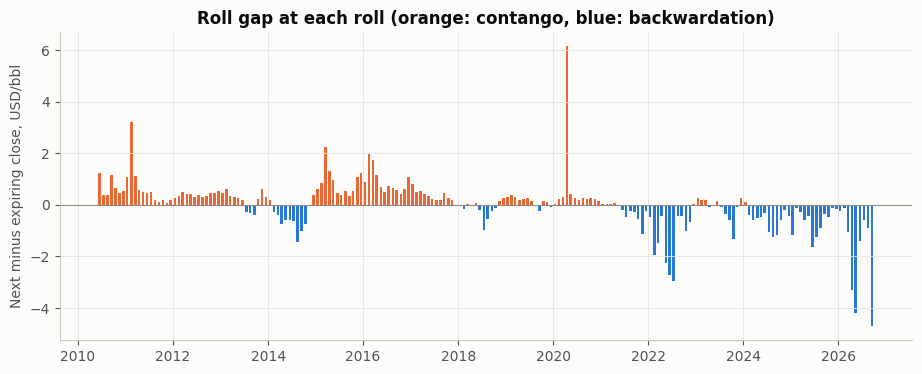

In [10]:
gap_stats = rolls["gap"].describe()
display(gap_stats.round(3).to_frame("roll gap, USD/bbl"))
print(f"Contango rolls: {(rolls['gap'] > 0).mean():.0%}; mean |gap| {rolls['gap'].abs().mean():.2f} USD/bbl "
      f"= {rolls['gap'].abs().mean() * 1000:,.0f} USD per contract")

fig, ax = plt.subplots()
colors = np.where(rolls["gap"] > 0, ADJUSTED, RAW)
ax.bar(rolls["roll_date"], rolls["gap"], width=20, color=colors)
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_title("Roll gap at each roll (orange: contango, blue: backwardation)")
ax.set_ylabel("Next minus expiring close, USD/bbl")
fig.savefig(figures / "daily_roll_gaps.png")
plt.show()

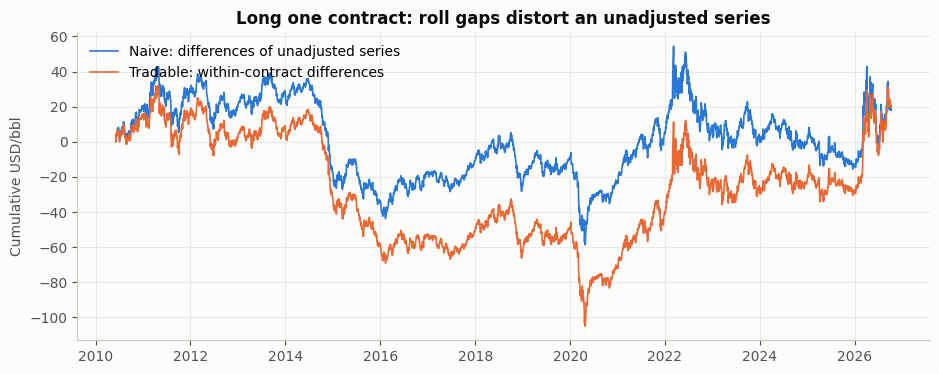

Difference at the end: -1.51 USD/bbl, equal to the sum of roll gaps -1.51


In [11]:
# Cumulative P&L per barrel: naive unadjusted close differences vs. within-contract (tradable) differences.
naive = continuous["close"].diff().fillna(0).cumsum()
tradable = returns["pnl_per_bbl"].fillna(0).cumsum()
fig, ax = plt.subplots()
ax.plot(continuous["trade_date"], naive, color=RAW, label="Naive: differences of unadjusted series")
ax.plot(continuous["trade_date"], tradable, color=ADJUSTED, label="Tradable: within-contract differences")
ax.set_title("Long one contract: roll gaps distort an unadjusted series")
ax.set_ylabel("Cumulative USD/bbl")
ax.legend(loc="upper left")
fig.savefig(figures / "daily_naive_vs_tradable.png")
plt.show()
print(f"Difference at the end: {naive.iloc[-1] - tradable.iloc[-1]:.2f} USD/bbl, equal to the sum of roll gaps {rolls['gap'].sum():.2f}")

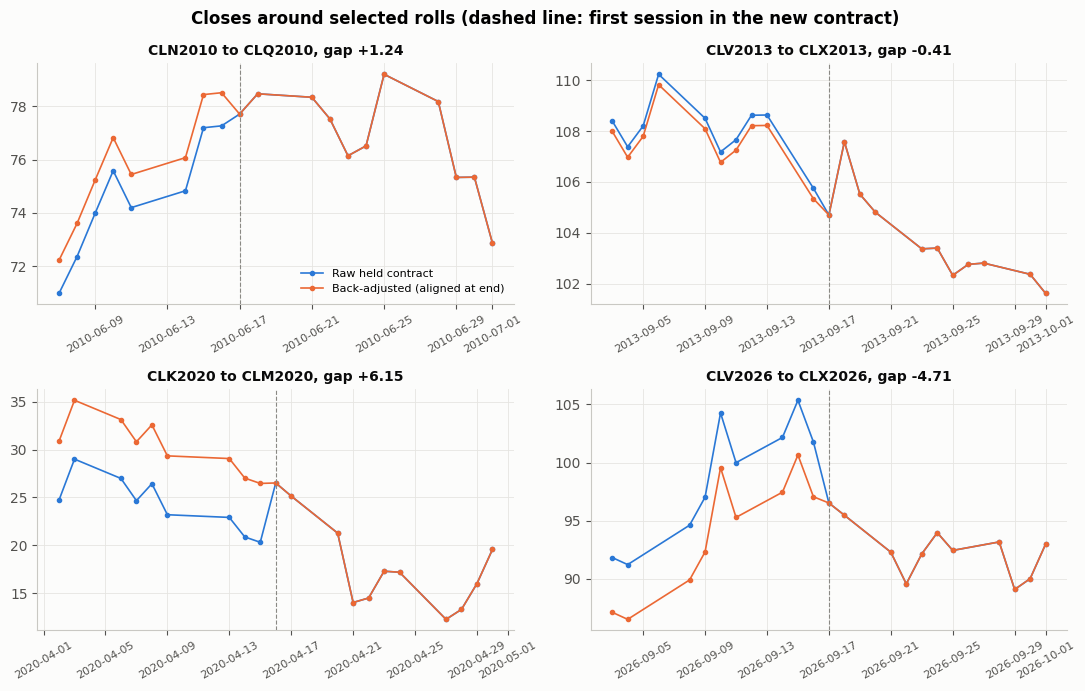

On roll dates, the adjusted series moves exactly by the new contract's own change: max difference 1.42e-14


In [12]:
# Raw and back-adjusted closes around several rolls: the adjusted series should have no jump.
# Largest contango gap, largest backwardation gap, a typical gap, and the first roll in the sample.
typical = (rolls["gap"].abs() - rolls["gap"].abs().median()).abs().idxmin()
examples = rolls.loc[[rolls["gap"].idxmax(), rolls["gap"].idxmin(), typical, rolls.index[0]]].sort_values("roll_date")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, roll in zip(axes.flat, examples.itertuples()):
    window = continuous[continuous["trade_date"].between(roll.roll_date - pd.Timedelta(days=14), roll.roll_date + pd.Timedelta(days=14))]
    shift = window["close"].iloc[-1] - window["signal_close"].iloc[-1]
    ax.plot(window["trade_date"], window["close"], color=RAW, marker="o", markersize=3, label="Raw held contract")
    ax.plot(window["trade_date"], window["signal_close"] + shift, color=ADJUSTED, marker="o", markersize=3, label="Back-adjusted (aligned at end)")
    ax.axvline(roll.roll_date, color="#8a8984", linewidth=0.8, linestyle="--")
    ax.set_title(f"{roll.from_contract} to {roll.to_contract}, gap {roll.gap:+.2f}", fontsize=10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0, 0].legend(loc="best", fontsize=8)
fig.suptitle("Closes around selected rolls (dashed line: first session in the new contract)", fontweight="bold")
fig.tight_layout()
fig.savefig(figures / "daily_roll_examples.png")
plt.show()

roll_jump = returns.loc[returns["roll_flag"], "signal_close"].values - returns.shift().loc[returns["roll_flag"], "signal_close"].values
same_day_new = returns.loc[returns["roll_flag"], "pnl_per_bbl"].values
print(f"On roll dates, the adjusted series moves exactly by the new contract's own change: max difference {np.nanmax(np.abs(roll_jump - same_day_new)):.2e}")

In [13]:
diff = crosscheck["databento_volume_minus_ours"]
print("Databento CL.v.0 roll date minus ours, in sessions:")
display(diff.value_counts().sort_index().to_frame("rolls"))
print(f"Our rolls happen {rolls['sessions_before_expiry'].mode()[0]} sessions before expiry; CL.v.0 typically rolls {diff.median():.0f} sessions later.")

Databento CL.v.0 roll date minus ours, in sessions:


,rolls
databento_volume_minus_ours,
-5,1
0,2
1,9
2,67
3,94
4,23


Our rolls happen 3 sessions before expiry; CL.v.0 typically rolls 3 sessions later.


## 7. Findings that affect strategy design

These findings come from the outputs above (sample 2010-06-07 to 2026-10-07, 4,110 held-contract sessions, 196 rolls).

1. **Data quality is good enough for a daily backtest.** No duplicates, no OHLC inconsistencies, no negative volume. Four trade dates have no data at all (2014-06-13 and 2014-09-23 to 25). All four fall on dates Databento reports as degraded. Another 27 held-contract sessions fall on degraded dates; they are flagged but kept. The four outliers in the held series (2020-03-09, 2021-11-26, 2022-03-09, 2026-03-06) are market-wide moves: the next contract moved by a similar amount on the same day.
2. **Daily bars are UTC calendar days, not CME sessions.** Sunday-evening and holiday fragments are folded into the next trade date. Even so, each bar's `close` is the price at 00:00 UTC (19:00 or 20:00 New York time), not the 14:30 ET settlement. Each bar's `open` is the price about two hours after Globex reopens. As a result, the gap from the previous close to the next open is almost zero (median 0.013%, 99th percentile 1.7%). In a daily backtest, "execute at the next open" is therefore close to "execute at today's close". The report should state this, and the intraday data will show whether it matters.
3. **Roll timing.** Volume moves to the next contract between 3 and 2 sessions before expiry: the expiring contract's median share of front-two volume is 61% at 3 sessions and 26% at 2. The proposed rule rolls 3 sessions before the last trade date. That is the last session where the expiring contract is still the more liquid one. The rule is known in advance, so it has no look-ahead. Databento's volume-based `CL.v.0` rolls a median 3 sessions later, on the expiry date itself.
4. **Roll gaps are large, so signals need the back-adjusted series and P&L needs raw prices.** The mean absolute roll gap is 0.62 USD/bbl (620 USD per contract), and the extremes are +6.15 (April 2020) and -4.71 (September 2026). The cumulative adjustment reaches -50 USD/bbl, which pushes the adjusted series below zero in 2016 and 2020. Use `signal_close` only for price differences, such as moving averages. Compute P&L and returns within one contract from the raw `close` (or `open` for fills).
5. **Volatility depends heavily on the regime.** Annualized volatility is 40% over the full sample but ranges from 19% (2013) to 89% (2020) and 59% (2026). Daily returns are fat-tailed (excess kurtosis 20.7, skew -0.61), with 26 days beyond ±10%. With a fixed one-contract position, a few high-volatility periods will dominate P&L. Results should be reported by subperiod, and the Sharpe ratio interpreted with care.
6. **Effect on the 70/30 split.** A session-based 70/30 split falls at 2021-11-08 (development) / 2021-11-09 (holdout). The holdout contains the 2022 and 2026 shocks, while the development period contains the 2014–16 collapse and 2020. Both periods include extreme regimes, which helps the comparison but makes the holdout result noisy.
7. **April 2020.** The roll rule leaves CLK2020 on 2020-04-16, so the held series never includes the negative price of 2020-04-20 (the lowest held close is 12.26). Backtest code should still handle prices that are zero or negative in case the roll rule changes.
8. **Intraday viability cannot be judged yet.** The daily file has no intraday timestamps, so it cannot show volume by time of day or test 15-minute bars. That needs an `ohlcv-1m` download, after a cost check. Held-contract volume is about 276k contracts a day (median), so liquidity is not a concern at the daily horizon.